In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Load Day 6 master dataset
data_path = Path(
    "../data/processed/us_macro_etf_master_2008_2025.csv"
)

master = pd.read_csv(
    data_path,
    parse_dates=["observation_date"]
)

master = master.sort_values(
    "observation_date"
).reset_index(drop=True)

# Check available statistical libraries
import scipy
import statsmodels

print("SciPy version:", scipy.__version__)
print("Statsmodels version:", statsmodels.__version__)

print("\nMaster dataset shape:", master.shape)

print("\nInflation regime distribution:")
print(master["inflation_regime"].value_counts())

print("\nMissing values:")
print(master[
    ["inflation_yoy", "fed_change_pp", "SPY", "IEF", "GLD"]
].isna().sum())

# Validate core data
assert len(master) == 216
assert master["observation_date"].is_unique
assert master[["SPY", "IEF", "GLD"]].notna().all().all()

# Reproduce the main Day 6 finding
low = master.loc[
    master["inflation_regime"] == "Low Inflation"
]

high = master.loc[
    master["inflation_regime"] == "High Inflation"
]

r_low = low["SPY"].corr(low["IEF"])
r_high = high["SPY"].corr(high["IEF"])

observed_difference = r_high - r_low

print("\nResearch Baseline:")
print(f"Low inflation correlation: {r_low:.3f}")
print(f"High inflation correlation: {r_high:.3f}")
print(f"Observed difference: {observed_difference:.3f}")


SciPy version: 1.16.3
Statsmodels version: 0.14.5

Master dataset shape: (216, 13)

Inflation regime distribution:
inflation_regime
Low Inflation         96
Moderate Inflation    86
High Inflation        33
Name: count, dtype: int64

Missing values:
inflation_yoy    1
fed_change_pp    0
SPY              0
IEF              0
GLD              0
dtype: int64

Research Baseline:
Low inflation correlation: -0.262
High inflation correlation: 0.421
Observed difference: 0.683


In [2]:

from scipy.stats import norm

# Sample sizes
n_low = len(low)
n_high = len(high)

# Fisher transformation
z_low = np.arctanh(r_low)
z_high = np.arctanh(r_high)

# 95% confidence intervals
critical_value = norm.ppf(0.975)

def fisher_ci(r, n):
    z = np.arctanh(r)
    se = 1 / np.sqrt(n - 3)

    lower = np.tanh(z - critical_value * se)
    upper = np.tanh(z + critical_value * se)

    return lower, upper

ci_low = fisher_ci(r_low, n_low)
ci_high = fisher_ci(r_high, n_high)

# Test difference between correlations
standard_error = np.sqrt(
    1 / (n_low - 3) + 1 / (n_high - 3)
)

z_statistic = (z_high - z_low) / standard_error
p_value = 2 * norm.sf(abs(z_statistic))

results = pd.DataFrame({
    "Regime": ["Low Inflation", "High Inflation"],
    "Observations": [n_low, n_high],
    "Correlation": [r_low, r_high],
    "CI Lower": [ci_low[0], ci_high[0]],
    "CI Upper": [ci_low[1], ci_high[1]]
})

print("95% Fisher Confidence Intervals:")
display(results.round(4))

print(f"Fisher Z-statistic: {z_statistic:.4f}")
print(f"Two-sided p-value: {p_value:.6f}")
print(f"Observed correlation difference: {r_high-r_low:.4f}")


95% Fisher Confidence Intervals:


,Regime,Observations,Correlation,CI Lower,CI Upper
0,Low Inflation,96,-0.2616,-0.4391,-0.0645
1,High Inflation,33,0.4212,0.0911,0.6679


Fisher Z-statistic: 3.4147
Two-sided p-value: 0.000639
Observed correlation difference: 0.6828


In [3]:

# Moving Block Bootstrap:
# Difference in SPY-IEF correlations
# High inflation minus low inflation

import numpy as np
import pandas as pd

rng_seed = 2026
B = 3000

spy = master["SPY"].to_numpy(dtype=float)
ief = master["IEF"].to_numpy(dtype=float)

is_low = (
    master["inflation_regime"] == "Low Inflation"
).to_numpy()

is_high = (
    master["inflation_regime"] == "High Inflation"
).to_numpy()

n = len(master)

def moving_block_bootstrap(block_length, seed):
    rng = np.random.default_rng(seed)
    differences = []

    n_blocks = int(np.ceil(n / block_length))

    for _ in range(B):

        # Draw starting positions
        starts = rng.integers(
            0, n, size=n_blocks
        )

        # Circular consecutive blocks
        indices = (
            starts[:, None]
            + np.arange(block_length)
        ) % n

        indices = indices.ravel()[:n]

        low_mask = is_low[indices]
        high_mask = is_high[indices]

        # Guard against insufficient observations
        if low_mask.sum() < 20 or high_mask.sum() < 10:
            continue

        spy_sample = spy[indices]
        ief_sample = ief[indices]

        r_l = np.corrcoef(
            spy_sample[low_mask],
            ief_sample[low_mask]
        )[0, 1]

        r_h = np.corrcoef(
            spy_sample[high_mask],
            ief_sample[high_mask]
        )[0, 1]

        if np.isfinite(r_l) and np.isfinite(r_h):
            differences.append(r_h - r_l)

    return np.array(differences)

bootstrap_results = []

for block_length in [6, 12]:

    boot_diff = moving_block_bootstrap(
        block_length,
        seed=rng_seed + block_length
    )

    ci_lower, ci_upper = np.percentile(
        boot_diff, [2.5, 97.5]
    )

    bootstrap_results.append({
        "block_length": block_length,
        "valid_replications": len(boot_diff),
        "observed_difference": observed_difference,
        "ci_lower": ci_lower,
        "ci_upper": ci_upper,
        "contains_zero": ci_lower <= 0 <= ci_upper
    })

bootstrap_summary = pd.DataFrame(
    bootstrap_results
)

print("Moving Block Bootstrap Results:")
display(bootstrap_summary.round(4))


Moving Block Bootstrap Results:


,block_length,valid_replications,observed_difference,ci_lower,ci_upper,contains_zero
0,6,2963,0.6828,0.1022,1.0299,False
1,12,2837,0.6828,0.0043,1.0543,False


In [4]:

import statsmodels.api as sm

# Prepare regression dataset
reg_df = master.dropna(
    subset=["inflation_regime", "SPY", "IEF"]
).sort_values("observation_date").copy()

# Regime indicators (Low Inflation = baseline)
reg_df["moderate"] = (
    reg_df["inflation_regime"] == "Moderate Inflation"
).astype(int)

reg_df["high"] = (
    reg_df["inflation_regime"] == "High Inflation"
).astype(int)

# Interaction terms
reg_df["SPY_moderate"] = (
    reg_df["SPY"] * reg_df["moderate"]
)

reg_df["SPY_high"] = (
    reg_df["SPY"] * reg_df["high"]
)

# Regression variables
X = reg_df[
    ["SPY", "moderate", "high",
     "SPY_moderate", "SPY_high"]
]

X = sm.add_constant(X)
y = reg_df["IEF"]

# HAC regressions with two lag specifications
hac_models = {}

for lag in [6, 12]:
    model = sm.OLS(y, X).fit(
        cov_type="HAC",
        cov_kwds={"maxlags": lag}
    )

    hac_models[lag] = model

# Compare coefficient estimates and inference
regression_results = pd.DataFrame({
    "Coefficient": hac_models[6].params,
    "HAC6_SE": hac_models[6].bse,
    "HAC6_pvalue": hac_models[6].pvalues,
    "HAC12_SE": hac_models[12].bse,
    "HAC12_pvalue": hac_models[12].pvalues
})

print("HAC Regression Results:")
display(regression_results.round(4))

# Implied SPY-IEF regression slopes
beta = hac_models[6].params

regime_slopes = pd.DataFrame({
    "Regime": [
        "Low Inflation",
        "Moderate Inflation",
        "High Inflation"
    ],
    "SPY_IEF_Slope": [
        beta["SPY"],
        beta["SPY"] + beta["SPY_moderate"],
        beta["SPY"] + beta["SPY_high"]
    ]
})

print("\nEstimated SPY-IEF Slopes by Regime:")
display(regime_slopes.round(4))

print("\nObservations:", int(hac_models[6].nobs))
print("R-squared:", round(hac_models[6].rsquared, 4))

assert len(reg_df) == 215


HAC Regression Results:


,Coefficient,HAC6_SE,HAC6_pvalue,HAC12_SE,HAC12_pvalue
const,0.4950,0.2124,0.0198,0.1898,0.0091
SPY,-0.1136,0.0441,0.0099,0.0393,0.0038
moderate,-0.1030,0.2876,0.7203,0.2703,0.7033
high,-0.5432,0.4137,0.1892,0.4389,0.2159
SPY_moderate,0.0553,0.0855,0.5179,0.0857,0.5184
SPY_high,0.2968,0.0932,0.0015,0.1043,0.0044



Estimated SPY-IEF Slopes by Regime:


,Regime,SPY_IEF_Slope
0,Low Inflation,-0.1136
1,Moderate Inflation,-0.0583
2,High Inflation,0.1832



Observations: 215
R-squared: 0.081


In [5]:

# Leave-One-Year-Out Regression Robustness

robustness_years = [2008, 2020, 2021, 2022, 2023]

predictors = [
    "SPY",
    "moderate",
    "high",
    "SPY_moderate",
    "SPY_high"
]

robustness_rows = []

for excluded_year in [None] + robustness_years:

    if excluded_year is None:
        sample = reg_df.copy()
        label = "Full Sample"
    else:
        sample = reg_df.loc[
            reg_df["observation_date"].dt.year
            != excluded_year
        ].copy()

        label = f"Exclude {excluded_year}"

    X_sample = sm.add_constant(
        sample[predictors],
        has_constant="add"
    )

    y_sample = sample["IEF"]

    row = {
        "Sample": label,
        "N": len(sample),
        "High_N": int(sample["high"].sum())
    }

    for lag in [6, 12]:

        model = sm.OLS(
            y_sample,
            X_sample
        ).fit(
            cov_type="HAC",
            cov_kwds={"maxlags": lag}
        )

        row[f"HAC{lag}_SPY_high"] = (
            model.params["SPY_high"]
        )

        row[f"HAC{lag}_pvalue"] = (
            model.pvalues["SPY_high"]
        )

    robustness_rows.append(row)

regression_robustness = pd.DataFrame(
    robustness_rows
)

print("Leave-One-Year-Out Regression Robustness:")
display(regression_robustness.round(4))


Leave-One-Year-Out Regression Robustness:


,Sample,N,High_N,HAC6_SPY_high,HAC6_pvalue,HAC12_SPY_high,HAC12_pvalue
0,Full Sample,215,33,0.2968,0.0015,0.2968,0.0044
1,Exclude 2008,203,26,0.3732,0.0000,0.3732,0.0000
2,Exclude 2020,203,33,0.3053,0.0022,0.3053,0.0058
3,Exclude 2021,203,24,0.3151,0.0012,0.3151,0.0041
4,Exclude 2022,203,21,0.1677,0.1066,0.1677,0.1133
5,Exclude 2023,203,28,0.2545,0.0045,0.2545,0.0067


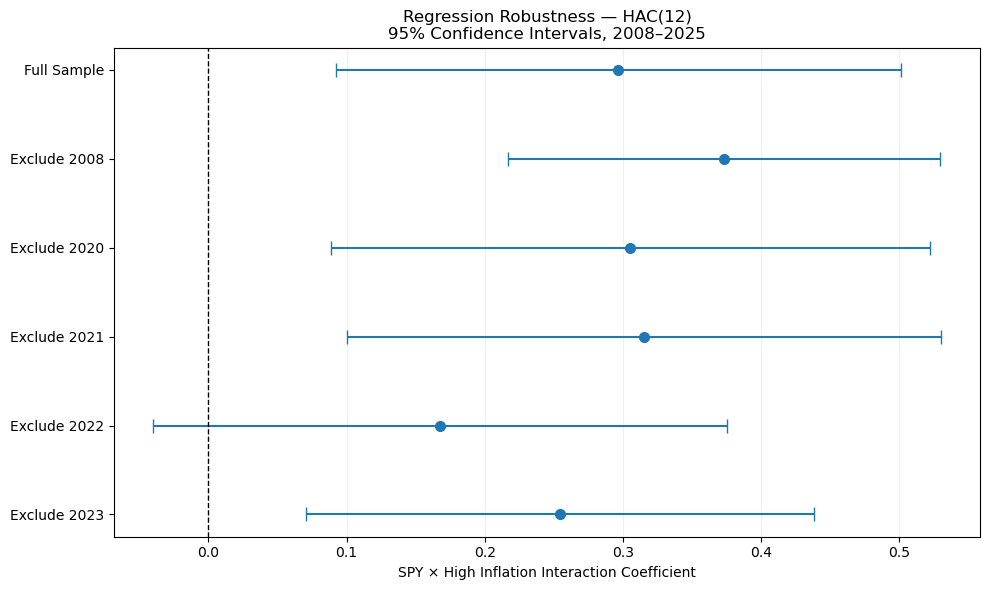

DAY 7 RESULTS SAVED SUCCESSFULLY

HAC(12) Confidence Intervals:


,Sample,Coefficient,CI_Lower,CI_Upper,p_value
0,Full Sample,0.2968,0.0923,0.5013,0.0044
1,Exclude 2008,0.3732,0.2166,0.5299,0.0000
2,Exclude 2020,0.3053,0.0885,0.5221,0.0058
3,Exclude 2021,0.3151,0.1002,0.5301,0.0041
4,Exclude 2022,0.1677,-0.0399,0.3752,0.1133
5,Exclude 2023,0.2545,0.0706,0.4385,0.0067


In [6]:

# Day 7 — Save Statistical Results and Robustness Figure

from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

tables_dir = Path("../reports/tables")
figures_dir = Path("../reports/figures")

tables_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

# Save statistical results
results.to_csv(
    tables_dir / "fisher_correlation_intervals.csv",
    index=False
)

bootstrap_summary.to_csv(
    tables_dir / "block_bootstrap_results.csv",
    index=False
)

regression_results.to_csv(
    tables_dir / "hac_regression_results.csv",
    index_label="coefficient_name"
)

regime_slopes.to_csv(
    tables_dir / "regime_regression_slopes.csv",
    index=False
)

regression_robustness.to_csv(
    tables_dir / "regression_robustness.csv",
    index=False
)

# Calculate HAC(12) confidence intervals
# for the leave-one-year-out regression

ci_rows = []

for excluded_year in [None, 2008, 2020, 2021, 2022, 2023]:

    if excluded_year is None:
        sample = reg_df.copy()
        label = "Full Sample"
    else:
        sample = reg_df.loc[
            reg_df["observation_date"].dt.year
            != excluded_year
        ].copy()
        label = f"Exclude {excluded_year}"

    X_sample = sm.add_constant(
        sample[predictors],
        has_constant="add"
    )

    model = sm.OLS(
        sample["IEF"], X_sample
    ).fit(
        cov_type="HAC",
        cov_kwds={"maxlags": 12}
    )

    ci = model.conf_int().loc["SPY_high"]

    ci_rows.append({
        "Sample": label,
        "Coefficient": model.params["SPY_high"],
        "CI_Lower": ci.iloc[0],
        "CI_Upper": ci.iloc[1],
        "p_value": model.pvalues["SPY_high"]
    })

robustness_ci = pd.DataFrame(ci_rows)

robustness_ci.to_csv(
    tables_dir / "regression_robustness_confidence_intervals.csv",
    index=False
)

# Forest plot
fig, ax = plt.subplots(figsize=(10, 6))

positions = np.arange(len(robustness_ci))

ax.errorbar(
    robustness_ci["Coefficient"],
    positions,
    xerr=[
        robustness_ci["Coefficient"] - robustness_ci["CI_Lower"],
        robustness_ci["CI_Upper"] - robustness_ci["Coefficient"]
    ],
    fmt="o",
    capsize=5,
    markersize=7
)

ax.axvline(
    0,
    linestyle="--",
    linewidth=1,
    color="black"
)

ax.set_yticks(positions)
ax.set_yticklabels(robustness_ci["Sample"])

ax.invert_yaxis()

ax.set_xlabel(
    "SPY × High Inflation Interaction Coefficient"
)

ax.set_title(
    "Regression Robustness — HAC(12)\n"
    "95% Confidence Intervals, 2008–2025"
)

ax.grid(axis="x", alpha=0.2)

fig.tight_layout()

fig.savefig(
    figures_dir / "regression_robustness_hac12.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("DAY 7 RESULTS SAVED SUCCESSFULLY")
print("\nHAC(12) Confidence Intervals:")
display(robustness_ci.round(4))



## Day 7 — Statistical Validation: Final Findings

### Research Question

Do stock-bond relationships differ significantly between low- and high-inflation environments in the United States during 2008–2025?

### 1. Fisher Z-Test

The observed SPY–IEF correlations were:

- Low Inflation: -0.262 (n = 96)
- High Inflation: +0.421 (n = 33)

The difference was +0.683.

A classical two-sided Fisher Z-test produced:

- Z-statistic: 3.4147
- p-value: 0.000639

The test rejects equality of the two correlations under its independence and distributional assumptions.

However, monthly financial observations and inflation regimes are not necessarily independent. Therefore, the classical p-value should not be interpreted as definitive evidence.

### 2. Moving Block Bootstrap

Circular moving block bootstrap was used to examine uncertainty while preserving some temporal dependence.

95% percentile confidence intervals for the correlation difference:

- 6-month blocks: [0.1022, 1.0299]
- 12-month blocks: [0.0043, 1.0543]

Both intervals excluded zero.

However, the 12-month interval was close to including zero, indicating sensitivity to bootstrap specification.

The procedure cannot resolve the limited number of independent inflationary episodes.

### 3. HAC Interaction Regression

An OLS model with inflation-regime indicators and SPY interaction terms was estimated using HAC standard errors.

The dependent variable was the monthly return of IEF.

Estimated SPY–IEF slopes:

- Low Inflation: -0.1136
- Moderate Inflation: -0.0583
- High Inflation: +0.1832

The SPY × High Inflation interaction coefficient was +0.2968.

Statistical inference:

- HAC(6) p-value: 0.0015
- HAC(12) p-value: 0.0044
- HAC(12) 95% CI: [0.0923, 0.5013]

The interaction coefficient was statistically significant in the full sample.

The model's R-squared was 0.081, indicating limited explanatory power for monthly bond returns.

Regression slopes and Pearson correlations are related but distinct measures.

### 4. Leave-One-Year-Out Robustness

The interaction coefficient remained positive when individual years were excluded.

However, excluding 2022 produced:

- Interaction coefficient: +0.1677
- HAC(12) p-value: 0.1133
- HAC(12) 95% CI: [-0.0399, 0.3752]

Thus, the coefficient was no longer statistically significant at the 5% level.

This indicates that the full-sample statistical finding is sensitive to the inclusion of 2022.

### 5. Methodological Limitations

- The analysis is observational and does not establish causality.
- High-inflation months are concentrated in relatively few historical episodes.
- Inflation regimes are defined using researcher-selected CPI thresholds.
- Contemporaneous CPI classifications are not real-time investment signals.
- The classical Fisher test assumes independent observations.
- Block bootstrap results depend on block length and sampling choices.
- Bootstrap resamples with insufficient regime observations were excluded.
- HAC standard errors do not eliminate omitted-variable bias or structural instability.
- Leave-one-year-out HAC estimates are approximate because excluding a year creates a gap in the calendar sequence.
- The interaction regression estimates conditional return slopes, not causal effects of inflation.
- Results are specific to the selected ETFs, sample period and US market environment.

### Final Research Conclusion

The empirical evidence indicates that the relationship between US equities and intermediate-term Treasury bonds differed across inflation regimes during 2008–2025.

The stock-bond relationship was negative during low-inflation months and positive during high-inflation months.

Classical correlation tests, moving block bootstrap intervals and HAC interaction regressions provided supporting statistical evidence in the full sample.

Nevertheless, the loss of statistical significance when excluding 2022 highlights substantial sensitivity to a major historical episode.

The findings are therefore best interpreted as historically informative rather than as evidence of a universal, stable or causal relationship.

### Implications for Portfolio Analysis

The results motivate further investigation of whether traditional stock-bond portfolios experienced weaker diversification benefits during high-inflation environments.

The next stage will evaluate portfolio-level performance, volatility, drawdowns and diversification outcomes.

Any subsequent investment backtests must distinguish historical regime descriptions from information actually available to investors at the time.
